<center>

# DSC670-T301 Advanced Uses of Generative AI (2267-1)

## Project Milestone 3

## Personalized Fitness & Home Workout Assistant:

### Dilip Kumar Balu

### 02-Aug-2026

</center>

# Project Milestone 3: Full Fine-Tuning of a Fitness-Coaching Model
 
**Base model:** `Qwen/Qwen3-0.6B`  
**Method:** Full supervised fine-tuning with Hugging Face Transformers  
**Environment:** Google Colab with a Tesla T4 GPU

## Project Objective

The objective of this milestone was to build a fully fine-tuned generative AI
model, track the model-building process, document the training and validation
metrics, and evaluate the trained model. I used a small conversational dataset
containing fitness-coaching prompts and structured workout responses.

The original milestone referenced OpenAI fine-tuning. After I encountered
account-level restrictions that prevented creation of an OpenAI fine-tuning
job, I received instructor approval to use Hugging Face Transformers as the
alternative platform. The implementation below performs full fine-tuning; it
does not use LoRA, QLoRA, PEFT, adapters, or quantized training.


## 1. Environment and Dataset Setup

I first uploaded the JSONL dataset and copied it to Google Drive so the file
would remain available if the Colab runtime disconnected.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving FitnessCoach-50_fixed.jsonl to FitnessCoach-50_fixed.jsonl


In [ ]:
from pathlib import Path

DATASET_PATH = Path("FitnessCoach-50_fixed.jsonl")

print("Dataset exists:", DATASET_PATH.exists())
print("Dataset path:", DATASET_PATH.resolve())

Dataset exists: True
Dataset path: /content/FitnessCoach-50_fixed.jsonl


In [ ]:
from google.colab import drive
import shutil

drive.mount("/content/drive")

DRIVE_DATASET_PATH = Path(
    "/content/drive/MyDrive/fitness_finetuning/FitnessCoach-50_fixed.jsonl"
)

DRIVE_DATASET_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copy(
    DATASET_PATH,
    DRIVE_DATASET_PATH
)

print("Dataset saved permanently to:")
print(DRIVE_DATASET_PATH)

Mounted at /content/drive
Dataset saved permanently to:
/content/drive/MyDrive/fitness_finetuning/FitnessCoach-50_fixed.jsonl


In [ ]:
DATASET_PATH = DRIVE_DATASET_PATH

## 2. Install and Import Packages


In [ ]:
%pip install -U transformers datasets accelerate matplotlib pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 5.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 129.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 18.4 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Su

In [ ]:
import json
import torch
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    DataCollatorForLanguageModeling,
    TrainingArguments,
    Trainer
)

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


## 3. Define Persistent Training Paths


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

DATASET_PATH = Path(
    "/content/drive/MyDrive/fitness_finetuning/FitnessCoach-50_fixed.jsonl"
)

TRAINING_OUTPUT_DIR = (
    "/content/drive/MyDrive/fitness_finetuning/"
    "fitness_coach_checkpoints"
)

FINAL_MODEL_DIR = (
    "/content/drive/MyDrive/fitness_finetuning/"
    "fitness_coach_full_finetuned"
)

print("Dataset exists:", DATASET_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset exists: True


## 4. Load and Split the Dataset


In [ ]:
raw_dataset = load_dataset(
    "json",
    data_files=str(DATASET_PATH),
    split="train"
)

dataset_split = raw_dataset.train_test_split(
    test_size=0.20,
    seed=42
)

train_dataset = dataset_split["train"]
validation_dataset = dataset_split["test"]

print("Training records:", len(train_dataset))
print("Validation records:", len(validation_dataset))

Generating train split: 0 examples [00:00, ? examples/s]

Training records: 40
Validation records: 10


The dataset contains 50 valid conversations. I used a reproducible random split
with 40 records for training and 10 records for validation. The dataset is
small and highly uniform: only 34 user prompts are unique, and all assistant
responses follow a similar warm-up, five-exercise, and cool-down template. This
uniformity is useful for teaching the desired format, but it also limits how
strongly the validation results can demonstrate generalization.


## 5. Load the Tokenizer and Format Conversations


In [ ]:
MODEL_NAME = "Qwen/Qwen3-0.6B"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

def format_conversation(example):
    text = tokenizer.apply_chat_template(
        example["messages"],
        tokenize=False,
        add_generation_prompt=False
    )
    return {"text": text}

formatted_train_dataset = train_dataset.map(format_conversation)
formatted_validation_dataset = validation_dataset.map(format_conversation)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

## 6. Tokenize the Conversations


In [ ]:
MAX_LENGTH = 1024

def tokenize_function(example):
    result = tokenizer(
        example["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH
    )

    result["labels"] = result["input_ids"].copy()
    return result

tokenized_train_dataset = formatted_train_dataset.map(
    tokenize_function,
    remove_columns=formatted_train_dataset.column_names
)

tokenized_validation_dataset = formatted_validation_dataset.map(
    tokenize_function,
    remove_columns=formatted_validation_dataset.column_names
)

Map:   0%|          | 0/40 [00:00<?, ? examples/s]

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

## 7. Load the Model for Full Fine-Tuning


In [ ]:
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32,
    trust_remote_code=True
)

model.config.use_cache = False
model.gradient_checkpointing_enable()
model = model.to("cuda")

print("Model device:", next(model.parameters()).device)
print("Model dtype:", next(model.parameters()).dtype)

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model device: cuda:0
Model dtype: torch.float32


All model parameters remained trainable. Mixed-precision training and gradient
checkpointing were used to reduce GPU-memory requirements, but no parameter-
efficient adapter or quantized-training method was used.


## 8. Configure the Hugging Face Trainer


In [ ]:
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False
)

training_args = TrainingArguments(
    output_dir=TRAINING_OUTPUT_DIR,

    num_train_epochs=3,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=5,

    learning_rate=2e-5,
    weight_decay=0.01,

    fp16=True,
    gradient_checkpointing=True,

    save_total_limit=3,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train_dataset,
    eval_dataset=tokenized_validation_dataset,
    data_collator=data_collator
)

print("Trainer ready.")

Trainer ready.


## 9. Train the Model

The model was trained for three epochs. With 40 training examples, a batch size
of one, and four gradient-accumulation steps, training completed 30 optimizer
steps. Checkpoints were saved after every epoch.


In [ ]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss
1,0.085336,0.063440
2,0.042268,0.039682
3,0.030888,0.032258


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].


## 10. Fine-Tuning Results

| Epoch | Training loss | Validation loss |
|---:|---:|---:|
| 1 | 0.085336 | 0.063440 |
| 2 | 0.042268 | 0.039682 |
| 3 | 0.030888 | 0.032258 |

The second full training run completed successfully on a Tesla T4 GPU in
approximately 9 minutes and 33 seconds. Training loss decreased from 0.085336
to 0.030888, while validation loss decreased from 0.063440 to 0.032258. There
was no divergence between the two loss curves on this validation split.

These low losses must be interpreted cautiously because the validation set has
only ten records and the dataset responses are highly repetitive. The results
show that the model learned the dataset pattern, but they do not by themselves
prove that the model will generalize to substantially different fitness
requests.

Transformers reported a missing `lm_head.weight` key while loading the best
checkpoint. This is associated with tied token-embedding and output-layer
weights. Training and checkpoint writing completed, and I verified the model by
successfully reloading it before inference.


## 11. Save and Verify the Fine-Tuned Model


In [ ]:
trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("Final model saved to:")
print(FINAL_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Final model saved to:
/content/drive/MyDrive/fitness_finetuning/fitness_coach_full_finetuned


In [ ]:
from pathlib import Path

saved_model_path = Path(FINAL_MODEL_DIR)

print("Model folder exists:", saved_model_path.exists())

for file_path in saved_model_path.iterdir():
    print(file_path.name)

Model folder exists: True
config.json
generation_config.json
model.safetensors
chat_template.jinja
tokenizer_config.json
tokenizer.json
training_args.bin


In [ ]:
import gc
import torch

# Remove training objects to free GPU memory
del trainer
del model

gc.collect()
torch.cuda.empty_cache()

from transformers import AutoTokenizer, AutoModelForCausalLM

fine_tuned_tokenizer = AutoTokenizer.from_pretrained(
    FINAL_MODEL_DIR
)

fine_tuned_model = AutoModelForCausalLM.from_pretrained(
    FINAL_MODEL_DIR,
    torch_dtype=torch.float16
).to("cuda")

fine_tuned_model.eval()

print("Fine-tuned model reloaded successfully.")
print("Device:", next(fine_tuned_model.parameters()).device)
print("Data type:", next(fine_tuned_model.parameters()).dtype)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Fine-tuned model reloaded successfully.
Device: cuda:0
Data type: torch.float16


In [ ]:
training_history = [
    {
        "epoch": 1,
        "training_loss": 0.085336,
        "validation_loss": 0.063440
    },
    {
        "epoch": 2,
        "training_loss": 0.042268,
        "validation_loss": 0.039682
    },
    {
        "epoch": 3,
        "training_loss": 0.030888,
        "validation_loss": 0.032258
    }
]

metrics_path = (
    "/content/drive/MyDrive/fitness_finetuning/"
    "huggingface_finetuning_metrics.json"
)

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(
        {
            "model": MODEL_NAME,
            "training_method": "Full fine-tuning",
            "epochs": 3,
            "training_steps": 30,
            "training_history": training_history
        },
        file,
        indent=2
    )

print("Metrics saved to:", metrics_path)

Metrics saved to: /content/drive/MyDrive/fitness_finetuning/huggingface_finetuning_metrics.json


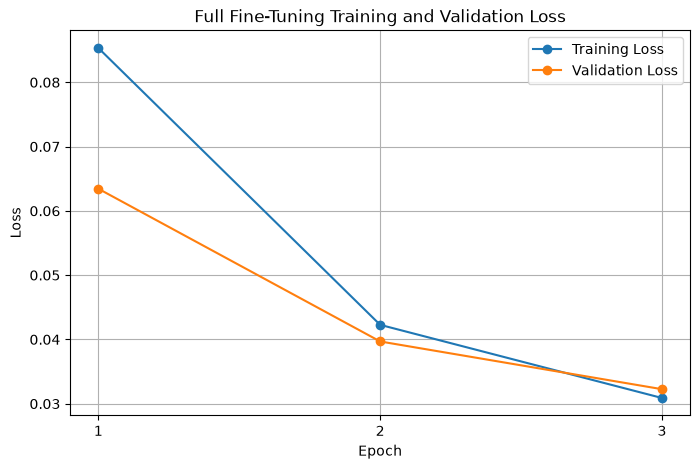

In [ ]:
metrics_df = pd.DataFrame(training_history)

plt.figure(figsize=(8, 5))

plt.plot(
    metrics_df["epoch"],
    metrics_df["training_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    metrics_df["epoch"],
    metrics_df["validation_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Full Fine-Tuning Training and Validation Loss")
plt.xticks([1, 2, 3])
plt.grid(True)
plt.legend()
plt.show()

During the project, the Colab runtime disconnected after training. Because the
epoch checkpoints and final model files had been written to Google Drive, I was
able to restore `checkpoint-30` without repeating the expensive training run.
The successful reload confirmed that the saved model was usable for inference.


## 12. Fine-Tuned Model Evaluation

I evaluated the model using three prompts that were different from the
minute-and-equipment phrasing used in the training dataset. The prompts request
multi-day plans, making them useful for checking whether the model learned only
the response template or could also follow new structural instructions.


In [ ]:
test_prompts = [
    "Generate a 5-day beginner workout plan for a 30-year-old female.",
    "Generate a 3-day full-body home workout plan for a 25-year-old male.",
    "Provide a 7-day cardio-focused workout routine for a 40-year-old female."
]

SYSTEM_PROMPT = (
    "You are a certified AI fitness coach that creates safe, "
    "clear, and effective workouts."
)

The inference function passes `input_ids` and `attention_mask` explicitly. This
is the corrected version of the function and avoids the earlier
`BatchEncoding.shape` error.


In [ ]:
def generate_workout_response(prompt):
    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    model_inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    model_inputs = {
        key: value.to("cuda")
        for key, value in model_inputs.items()
    }

    input_length = model_inputs["input_ids"].shape[1]

    with torch.no_grad():
        generated_ids = fine_tuned_model.generate(
            input_ids=model_inputs["input_ids"],
            attention_mask=model_inputs.get("attention_mask"),
            max_new_tokens=900,
            temperature=0.7,
            do_sample=True,
            top_p=0.9,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    new_tokens = generated_ids[0, input_length:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

In [ ]:
fine_tuned_outputs = []

for number, prompt in enumerate(test_prompts, start=1):
    output = generate_workout_response(prompt)

    fine_tuned_outputs.append({
        "prompt_number": number,
        "prompt": prompt,
        "response": output
    })

    print("=" * 100)
    print(f"TEST PROMPT {number}")
    print(prompt)
    print("-" * 100)
    print(output)

TEST PROMPT 1
Generate a 5-day beginner workout plan for a 30-year-old female.
----------------------------------------------------------------------------------------------------
<think>

</think>

**Workout Plan (5 days, 30 years, female)**

**Warm-Up**
- High Knees – 1 min
- Shoulder Rolls – 1 min
- Hip Circles – 1 min

**Main Workout**
1. **Glute Bridge** ⏱️ Work: 45s | Rest: 15s
Step 1: Start position for glute bridge.
Step 2: Perform the main movement for glute bridge.
Step 3: Return to starting position and repeat.

2. **Mountain Climbers** ⏱️ Work: 45s | Rest: 15s
Step 1: Start position for mountain climbers.
Step 2: Perform the main movement for mountain climbers.
Step 3: Return to starting position and repeat.

3. **Lunges** ⏱️ Work: 45s | Rest: 15s
Step 1: Start position for lunges.
Step 2: Perform the main movement for lunges.
Step 3: Return to starting position and repeat.

4. **Push-Ups** ⏱️ Work: 45s | Rest: 15s
Step 1: Start position for push-ups.
Step 2: Perform the ma

In [ ]:
import json
from pathlib import Path

EVALUATION_FILE = Path(
    "/content/drive/MyDrive/fitness_finetuning/"
    "fine_tuned_model_evaluation.json"
)

with EVALUATION_FILE.open("w", encoding="utf-8") as file:
    json.dump(
        fine_tuned_outputs,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Evaluation saved to:", EVALUATION_FILE)

Evaluation saved to: /content/drive/MyDrive/fitness_finetuning/fine_tuned_model_evaluation.json


## 13. Base-Model Evaluation

For a direct comparison, I used the original `Qwen/Qwen3-0.6B` model with the
same system prompt, test prompts, temperature, top-p value, and maximum token
limit. I moved the fine-tuned model to the CPU before loading the base model to
avoid unnecessary GPU-memory pressure.


In [ ]:
fine_tuned_model = fine_tuned_model.to("cpu")

import gc
import torch

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared.")

GPU memory cleared.


In [ ]:
from transformers import AutoModelForCausalLM

BASE_MODEL_NAME = "Qwen/Qwen3-0.6B"

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL_NAME,
    torch_dtype=torch.float16,
    trust_remote_code=True
).to("cuda")

base_model.eval()

print("Base model loaded successfully.")
print("Device:", next(base_model.parameters()).device)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Base model loaded successfully.
Device: cuda:0


In [ ]:
def generate_base_response(prompt):
    messages = [
        {
            "role": "system",
            "content": SYSTEM_PROMPT
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    model_inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    model_inputs = {
        key: value.to("cuda")
        for key, value in model_inputs.items()
    }

    input_length = model_inputs["input_ids"].shape[1]

    with torch.no_grad():
        generated_ids = base_model.generate(
            input_ids=model_inputs["input_ids"],
            attention_mask=model_inputs.get("attention_mask"),
            max_new_tokens=900,
            temperature=0.7,
            do_sample=True,
            top_p=0.9,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )

    new_tokens = generated_ids[0, input_length:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

In [ ]:
base_outputs = []

for number, prompt in enumerate(test_prompts, start=1):
    output = generate_base_response(prompt)

    base_outputs.append({
        "prompt_number": number,
        "prompt": prompt,
        "response": output
    })

    print("=" * 100)
    print(f"BASE MODEL — TEST PROMPT {number}")
    print(prompt)
    print("-" * 100)
    print(output)

BASE MODEL — TEST PROMPT 1
Generate a 5-day beginner workout plan for a 30-year-old female.
----------------------------------------------------------------------------------------------------
<think>
Okay, the user wants a 5-day beginner workout plan for a 30-year-old female. Let me start by understanding her age and fitness level. She's 30, so she's likely in her early 30s, which is a prime age for fitness. But she's a beginner, so she might not have much experience.

First, I need to consider her current fitness level. Since she's a beginner, the plan should be safe and not too intense. It should include a mix of strength, cardio, and flexibility. Maybe start with a mix of cardio and strength training to build overall fitness.

The user might not have a gym, so I should suggest online resources or home workouts. Also, they might not have time for long sessions, so shorter, focused sessions are better. The plan should be adaptable for different home environments.

I need to make sure

In [ ]:
from pathlib import Path
import json

BASE_EVALUATION_FILE = Path(
    "/content/drive/MyDrive/fitness_finetuning/"
    "base_model_evaluation.json"
)

with BASE_EVALUATION_FILE.open(
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        base_outputs,
        file,
        indent=2,
        ensure_ascii=False
    )

print("Base-model evaluation saved to:")
print(BASE_EVALUATION_FILE)

Base-model evaluation saved to:
/content/drive/MyDrive/fitness_finetuning/base_model_evaluation.json


## 14. Side-by-Side Response Comparison


In [ ]:
comparison_rows = []

for i in range(len(test_prompts)):
    comparison_rows.append(
        {
            "Prompt": test_prompts[i],
            "Base model": base_outputs[i]["response"],
            "Fine-tuned model": fine_tuned_outputs[i]["response"],
        }
    )

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

,Prompt,Base model,Fine-tuned model
0,Generate a 5-day beginner workout plan for a 3...,"<think>\nOkay, the user wants a 5-day beginner...","<think>\n\n</think>\n\n**Workout Plan (5 days,..."
1,Generate a 3-day full-body home workout plan f...,"<think>\nOkay, the user wants a 3-day full-bod...","<think>\n\n</think>\n\n**Workout Plan (3 days,..."
2,Provide a 7-day cardio-focused workout routine...,"<think>\nOkay, the user is asking for a 7-day ...","<think>\n\n</think>\n\n**Workout Plan (7 days,..."


In [ ]:
comparison_file = (
    "/content/drive/MyDrive/fitness_finetuning/"
    "base_vs_finetuned_comparison.csv"
)

comparison_df.to_csv(comparison_file, index=False)

print("Saved to:", comparison_file)

Saved to: /content/drive/MyDrive/fitness_finetuning/base_vs_finetuned_comparison.csv


## 15. Qualitative Evaluation

The response comparison produced a mixed result. The fine-tuned model learned
the desired presentation style, but the test also exposed weaknesses that are
not visible from validation loss alone.

| Criterion | Base model | Fine-tuned model |
|---|---|---|
| Format consistency | Verbose and inconsistent across prompts | Consistently used warm-up, timed workout, rest, and cool-down sections |
| Multi-day instruction adherence | Attempted to create separate days, but responses were verbose and reached the generation limit before every plan was completed | Labeled responses as 3-day, 5-day, or 7-day plans but returned only one workout session |
| Prompt specificity | More responsive to day count and cardio focus | Frequently reused the same five-exercise template regardless of the requested focus |
| Practicality and safety | Sometimes suggested unrealistic session lengths, unnecessary equipment, or overly demanding beginner exercises | More concise, but exercise directions were generic and did not explain proper form |
| Consistency with training data | Less consistent | Strongly consistent with the dataset style |

I did not treat keyword coverage as model accuracy or calculate a “simulated
loss.” Counting selected exercise names would favor the repetitive training
template and would not measure whether a response actually followed a request
for a multi-day or cardio-focused plan. The actual model losses are the
training and validation losses reported by the Trainer.


## 16. Save the Complete Project Summary


In [ ]:
summary = {
    "base_model": "Qwen/Qwen3-0.6B",
    "fine_tuning_platform": "Hugging Face Transformers",
    "fine_tuning_method": "Full supervised fine-tuning",
    "training_records": 40,
    "validation_records": 10,
    "epochs": 3,
    "training_steps": 30,
    "training_history": training_history,
    "test_prompts": test_prompts,
    "base_outputs": base_outputs,
    "fine_tuned_outputs": fine_tuned_outputs,
    "qualitative_findings": {
        "improvement": "More consistent workout formatting and concise structure",
        "limitation": "Did not reliably create separate days or follow cardio-specific requests",
        "interpretation": "Fine-tuning improved style consistency more than instruction adherence"
    }
}

summary_path = Path(
    "/content/drive/MyDrive/fitness_finetuning/"
    "complete_finetuning_summary.json"
)

with summary_path.open("w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2, ensure_ascii=False)

print("Complete summary saved to:")
print(summary_path)


Complete summary saved to:
/content/drive/MyDrive/fitness_finetuning/complete_finetuning_summary.json


## 17. Final Conclusion

For this milestone, I completed full supervised fine-tuning of
`Qwen/Qwen3-0.6B` using Hugging Face Transformers. I used the Hugging Face
platform after receiving instructor approval to use it instead of OpenAI. I did
not use LoRA, QLoRA, PEFT, adapters, or quantized training; the complete model
was trained.

The dataset contained 50 fitness-coaching conversations, with 40 used for
training and 10 for validation. The model trained for three epochs and 30 steps
on a Tesla T4 GPU. Training loss decreased from 0.085336 to 0.030888, and
validation loss decreased from 0.063440 to 0.032258. The checkpoint and final
model were saved to Google Drive and successfully reloaded after a Colab runtime
disconnection.

The evaluation showed that fine-tuning improved formatting consistency. The
fine-tuned model reliably produced concise warm-up, main-workout, rest, and
cool-down sections that resembled the training examples. However, it did not
reliably follow the new multi-day instructions. The 3-day, 5-day, and 7-day
requests generally resulted in one workout session labeled with the requested
number of days. The cardio-focused request also reused several strength-
oriented exercises.

The base model was more likely to attempt separate daily plans and respond to
the requested workout focus, but its responses were overly verbose, sometimes
incomplete because they reached the generation limit, and occasionally
included unrealistic schedules or unnecessary equipment. Therefore, the final
result is mixed: full fine-tuning successfully taught the desired response
style, but it improved style consistency more than instruction adherence.

The main limitation is the small and repetitive dataset. A stronger future
dataset should contain diverse, complete multi-day programs, exercise-specific
form guidance, beginner modifications, equipment constraints, safety notes,
and cardio-focused examples. This project demonstrates that decreasing
validation loss is useful evidence of learning, but qualitative testing is also
necessary to determine whether the model follows new instructions correctly.


## 18. Provider Selection Commentary

I initially attempted to create the model through OpenAI. The training file
uploaded successfully, but OpenAI returned HTTP 403 with the error
`training_not_available`, which prevented my organization from creating a new
fine-tuning job.

I also completed a fine-tuning job through Together AI, but evaluation required
a dedicated endpoint. Endpoint creation was blocked by the account-level error
`endpoints_v1_create_access_disabled`.

After discussing these platform restrictions, I received instructor approval
to use Hugging Face instead of OpenAI. Hugging Face Transformers in Google
Colab allowed me to complete full fine-tuning, capture real training and
validation losses, save epoch checkpoints, reload the trained model, and
compare it directly with the original base model.
